---

# Detección de Anomalías y Mantenimiento Predictivo en Bombas Industriales mediante Redes Neuronales (MLP, CNN, RNN)

**Autor:** Witman Zavala M.

---

### PASO 1: Problema, Motivación y Justificación

**1. Contexto y Utilidad de la Solución**
El mantenimiento de equipos industriales es fundamental para evitar fallas inesperadas, interrupciones de producción y altos costos asociados a reparaciones. Este proyecto utiliza el conjunto de datos **Pump Sensor Data**, el cual contiene más de 220.000 registros temporales continuos provenientes de 52 sensores (vibración, corriente, voltaje, presión, etc.) instalados en una bomba de agua. La utilidad práctica de este modelo es habilitar un sistema de mantenimiento predictivo capaz de evaluar el comportamiento histórico de los sensores para identificar el estado de la máquina y detectar anomalías de manera temprana.
https://www.kaggle.com/datasets/nphantawee/pump-sensor-data

**2. Pregunta del Proyecto**
¿Es posible clasificar de manera confiable el estado operativo actual y anticipar anomalías en una bomba industrial analizando la secuencia temporal multivariada de sus sensores mediante arquitecturas profundas?

**3. Variable Objetivo ($y$)**
Nos enfrentamos a un problema de **Clasificación Multiclase**, donde la variable objetivo es `machine_status`, la cual representa el estado de la bomba en cada instante de tiempo:

* `NORMAL`: Funcionamiento óptimo.
* `RECOVERING`: Equipo en proceso de recuperación tras una falla.
* `BROKEN`: Equipo averiado.

**4. Justificación del Uso de Deep Learning**
La elección de Deep Learning para este proyecto no es por conveniencia, sino una necesidad dictada por la naturaleza del problema. Se justifica bajo los siguientes argumentos:

* **Cantidad y complejidad de datos:** Disponemos de un volumen masivo de datos (cientos de miles de registros) con 52 variables interactuando simultáneamente. Los patrones previos a una falla en una bomba industrial son altamente no triviales y multidimensionales.
* **Modalidad del dato:** La información corresponde a series temporales multivariadas. Esta modalidad secuencial favorece nativamente el aprendizaje de representaciones (representational learning), permitiendo a las redes descubrir dinámicas subyacentes sin depender de ingeniería de características manual.
* **Limitaciones de un modelo convencional:** Los modelos tradicionales (como regresiones o árboles superficiales) analizan cada registro temporal de forma aislada, perdiendo el contexto cronológico. Si bien se pueden usar ventanas temporales para crear características estadísticas (como se demostrará en el Baseline), estos modelos convencionales son incapaces de comprender el *orden* de los eventos y la evolución de la degradación física del equipo a través del tiempo.
* **Capacidad específica de las arquitecturas:**
* **MLP:** Servirá para evaluar si combinaciones no lineales simples sobre una ventana aplanada son suficientes para clasificar el estado operativo.
* **CNN 1D:** Su capacidad de convolución temporal permitirá extraer características espaciales locales, siendo ideal para detectar picos anómalos abruptos o cambios de frecuencia repentinos en los sensores.
* **RNN (LSTM/GRU):** Aportará la memoria secuencial necesaria para modelar la degradación progresiva de la máquina, reteniendo el contexto a largo plazo de las variables físicas justo antes de alcanzar un estado `BROKEN`.



---


## PASO 2 — INSTALACIÓN DE DEPENDENCIAS

In [1]:
# ============================================================
# PASO 2.1 — INSTALACIÓN DE DEPENDENCIAS
# ============================================================
# Instalamos los paquetes necesarios de manera silenciosa (-q)
!pip install -q lightning mlflow optuna xgboost scikit-learn

# ============================================================
# PASO 2.2 — IMPORTACIÓN BASE Y REPRODUCIBILIDAD (CRÍTICO)
# ============================================================
import pandas as pd                  # Manejo y análisis de datos mediante DataFrames
import numpy as np                   # Cálculos numéricos y manejo de arreglos/matrices
import matplotlib.pyplot as plt      # Creación de gráficos y visualizaciones
import torch                         # Librería de aprendizaje profundo (PyTorch)
import lightning as L                # Framework para organizar y entrenar modelos PyTorch
import mlflow                        # Seguimiento y registro de experimentos y modelos
import os                            # Interacción con el sistema operativo
import requests                      # Para descargas HTTP
import io                            # Manejo de flujos de bytes

from lightning.pytorch import seed_everything       # Fija las semillas aleatorias para reproducibilidad
from lightning.pytorch.loggers import MLFlowLogger   # Permite registrar métricas en MLflow

# Fijamos la semilla global para garantizar que los resultados
# sean idénticos en cada ejecución (reproducibilidad estricta).
SEMILLA = 42
seed_everything(SEMILLA, workers=True)

print("✅ Librerías importadas correctamente.")
print(f"⚡ Lightning versión: {L.__version__}")
print(f"📊 MLflow versión: {mlflow.__version__}")
print(f"🌱 Semilla global fijada en: {SEMILLA}")

# ============================================================
# PASO 2.3 — VERIFICACIÓN DE GPU / CUDA
# ============================================================
cuda_disponible = torch.cuda.is_available()
print("\n==============================================")
print("¿CUDA disponible?:", cuda_disponible)

if cuda_disponible:
    nombre_gpu = torch.cuda.get_device_name(0)
    memoria_gpu = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print("GPU disponible:", nombre_gpu)
    print(f"Memoria total de GPU: {memoria_gpu:.2f} GB")
else:
    print("⚠️ No se detectó una GPU.")
    print("El entrenamiento se ejecutará utilizando CPU.")
print("==============================================\n")

# ============================================================
# PASO 2.4 — CONFIGURACIÓN DE MLFLOW
# ============================================================
# 1. Definir la base de datos local de MLflow (SQLite)
MLFLOW_DB = "sqlite:///mlflow.db"

# 2. Configurar el tracking URI
mlflow.set_tracking_uri(MLFLOW_DB)

# 3. Definir el nombre del experimento
EXPERIMENT_NAME = "Pump_Sensor_Predictive_Maintenance"
mlflow.set_experiment(EXPERIMENT_NAME)

# 4. Verificación Final
print("✅ MLFLOW CONFIGURADO CORRECTAMENTE")
print(f"Experimento: {EXPERIMENT_NAME}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 kB 5.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.5/50.5 kB 5.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 848.6/848.6 kB 61.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 163.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 127.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 102.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 43.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 31.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 132.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42


✅ Librerías importadas correctamente.
⚡ Lightning versión: 2.6.5
📊 MLflow versión: 3.15.1
🌱 Semilla global fijada en: 42

¿CUDA disponible?: True
GPU disponible: NVIDIA A100-SXM4-40GB
Memoria total de GPU: 39.49 GB



2026/08/23 21:59:10 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/08/23 21:59:10 INFO mlflow.store.db.utils: Updating database tables
2026/08/23 21:59:12 INFO mlflow.tracking.fluent: Experiment with name 'Pump_Sensor_Predictive_Maintenance' does not exist. Creating a new experiment.


✅ MLFLOW CONFIGURADO CORRECTAMENTE
Experimento: Pump_Sensor_Predictive_Maintenance


## 2.1 Ingesta y Limpieza de Datos

In [2]:
# ============================================================
# PASO 2.5 — CARGA DEL DATASET DESDE GOOGLE DRIVE
# ============================================================
FILE_ID = "1MTvPGKRDb5eS2eZINnXaPymzBXpVmYhc"
DOWNLOAD_URL = f"https://drive.usercontent.google.com/download?id={FILE_ID}&export=download&confirm=t"

print("Descargando archivo Pump Sensor Data...")
response = requests.get(DOWNLOAD_URL, timeout=120)

if response.status_code != 200:
    raise Exception("❌ No fue posible descargar el archivo desde Google Drive.")
print("✅ Archivo descargado correctamente.")

archivo_csv = io.BytesIO(response.content)
df = pd.read_csv(archivo_csv, low_memory=False)

print(f"Filas originales: {df.shape[0]:,}")
print(f"Columnas originales: {df.shape[1]:,}")

# ============================================================
# PASO 2.6 — LIMPIEZA Y TRATAMIENTO DE NULOS
# ============================================================
# 1. Eliminar columnas inservibles
COLUMNAS_ELIMINAR = ["Unnamed: 0", "sensor_15", "sensor_50"]
columnas_existentes = [col for col in COLUMNAS_ELIMINAR if col in df.columns]
df = df.drop(columns=columnas_existentes)

# 2. Conversión de Timestamp y orden cronológico estricto (Previene Fuga de Información)
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df = df.sort_values(by="timestamp").reset_index(drop=True)

# 3. Preparar índice temporal para interpolación
df = df.set_index("timestamp")

# 4. Interpolación de sensores
columnas_sensores = [col for col in df.columns if col.startswith("sensor_")]

# Interpolar usando el tiempo (huecos internos) y rellenar extremos
df[columnas_sensores] = df[columnas_sensores].interpolate(method="time", limit_area="inside")
df[columnas_sensores] = df[columnas_sensores].bfill().ffill()

# Validación de nulos restantes
faltantes_finales = df[columnas_sensores].isna().sum().sum()
if faltantes_finales == 0:
    print("✅ No existen valores faltantes en los sensores tras la limpieza.")
else:
    print(f"⚠️ Aún quedan {faltantes_finales} valores nulos en sensores.")

# ============================================================
# PASO 2.7 — CODIFICACIÓN DE LA VARIABLE OBJETIVO
# ============================================================
VARIABLE_OBJETIVO = "machine_status"

# Diccionario de mapeo para clasificación multiclase (0, 1, 2)
MAPEO_ESTADO = {
    "NORMAL": 0,
    "BROKEN": 1,
    "RECOVERING": 2
}

df[VARIABLE_OBJETIVO] = df[VARIABLE_OBJETIVO].map(MAPEO_ESTADO)
nulos_objetivo = df[VARIABLE_OBJETIVO].isna().sum()

print("\n==============================================")
print("       DISTRIBUCIÓN DE MACHINE_STATUS")
print("==============================================")
display(df[VARIABLE_OBJETIVO].value_counts(normalize=True).mul(100).round(2))

if nulos_objetivo == 0:
    print("\n✅ Codificación a tensores numéricos exitosa (0=NORMAL, 1=BROKEN, 2=RECOVERING).")
else:
    print(f"\n❌ Existen {nulos_objetivo} valores no reconocidos tras el mapeo.")

# Reseteamos el índice para recuperar 'timestamp' como columna
# Esto será vital para las particiones temporales del próximo paso.
df = df.reset_index()

Descargando archivo Pump Sensor Data...
✅ Archivo descargado correctamente.
Filas originales: 220,320
Columnas originales: 55
✅ No existen valores faltantes en los sensores tras la limpieza.

       DISTRIBUCIÓN DE MACHINE_STATUS


,proportion
machine_status,
0,93.43
2,6.57
1,0.00



✅ Codificación a tensores numéricos exitosa (0=NORMAL, 1=BROKEN, 2=RECOVERING).


# PASO 3: Partición Estratégica por Ciclos de Falla

Total de fallas (BROKEN) detectadas: 7
Índices de fallas: [17155, 24510, 69318, 77790, 128040, 141131, 166440]

Distribución de particiones:
Train : 131,040 registros (59.5%)
Val   : 13,091 registros (5.9%)
Test  : 76,189 registros (34.6%)

Verificación de clases en Test (debe contener 0, 1 y 2):
machine_status
0    76113
2       75
1        1
Name: count, dtype: int64


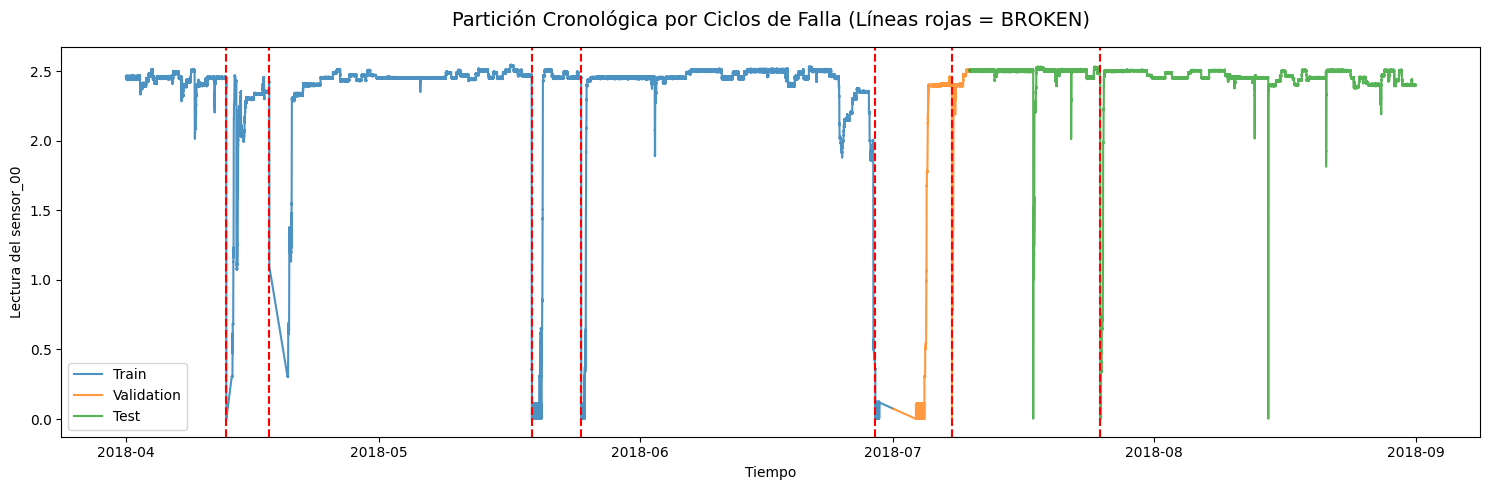

In [3]:
# ============================================================
# PASO 3.1 — IDENTIFICACIÓN DE CICLOS DE FALLA
# ============================================================
# Buscamos los índices exactos donde la máquina entró en estado BROKEN (1)
fallas_idx = df[df[VARIABLE_OBJETIVO] == 1].index.tolist()

print("==============================================")
print(f"Total de fallas (BROKEN) detectadas: {len(fallas_idx)}")
print(f"Índices de fallas: {fallas_idx}")
print("==============================================")

# ============================================================
# PASO 3.2 — PARTICIÓN TEMPORAL ESTRICTA
# ============================================================
# En lugar de un 70/15/15 ciego, cortaremos la serie de tiempo en
# períodos "NORMALES" entre las fallas para asegurar que cada
# partición contenga ejemplos de los 3 estados operativos.

# Corte 1: Después de la 5ta falla (dejamos ~3000 minutos de margen para que termine de recuperarse)
idx_corte_1 = fallas_idx[4] + 3000

# Corte 2: Después de la 6ta falla
idx_corte_2 = fallas_idx[5] + 3000

# Partición secuencial (evita data leakage)
train_df = df.iloc[:idx_corte_1].copy()
val_df = df.iloc[idx_corte_1:idx_corte_2].copy()
test_df = df.iloc[idx_corte_2:].copy()

print("\nDistribución de particiones:")
print(f"Train : {len(train_df):,} registros ({len(train_df)/len(df)*100:.1f}%)")
print(f"Val   : {len(val_df):,} registros ({len(val_df)/len(df)*100:.1f}%)")
print(f"Test  : {len(test_df):,} registros ({len(test_df)/len(df)*100:.1f}%)")

# ============================================================
# PASO 3.3 — VERIFICACIÓN DEL SOPORTE DE CLASES
# ============================================================
print("\nVerificación de clases en Test (debe contener 0, 1 y 2):")
print(test_df[VARIABLE_OBJETIVO].value_counts())

# ============================================================
# PASO 3.4 — VISUALIZACIÓN DE LA PARTICIÓN
# ============================================================
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

# Graficamos un sensor representativo
sensor_ref = "sensor_00"

plt.plot(train_df["timestamp"], train_df[sensor_ref], label="Train", color="#1f77b4", alpha=0.8)
plt.plot(val_df["timestamp"], val_df[sensor_ref], label="Validation", color="#ff7f0e", alpha=0.8)
plt.plot(test_df["timestamp"], test_df[sensor_ref], label="Test", color="#2ca02c", alpha=0.8)

# Marcamos las fallas con líneas rojas
for falla in fallas_idx:
    tiempo_falla = df.loc[falla, "timestamp"]
    plt.axvline(x=tiempo_falla, color="red", linestyle="--", linewidth=1.5)

plt.title("Partición Cronológica por Ciclos de Falla (Líneas rojas = BROKEN)", fontsize=14, pad=15)
plt.xlabel("Tiempo")
plt.ylabel(f"Lectura del {sensor_ref}")
plt.legend()
plt.tight_layout()
plt.show()

#PASO 4:Estandarización y Generación de Ventanas Temporales

In [4]:
# ============================================================
# PASO 4.1 — ESTANDARIZACIÓN ROBUSTA DE SEÑALES
# ============================================================

# Importa RobustScaler para escalar variables numéricas de forma robusta frente a valores atípicos (outliers)
from sklearn.preprocessing import RobustScaler
# Importa PyTorch, biblioteca utilizada para construir y entrenar redes neuronales
import torch
# Dataset permite definir conjuntos de datos personalizados y DataLoader facilita cargarlos en lotes (batches)
from torch.utils.data import Dataset, DataLoader
# Importa PyTorch Lightning, framework que simplifica la organización y entrenamiento de modelos de deep learning
import lightning as L

# Extraemos solo las columnas correspondientes a sensores (52 variables)
columnas_sensores = [col for col in df.columns if col.startswith("sensor_")]

# IMPORTANTE (Prevención de Leakage):
# Ajustamos el escalador ÚNICAMENTE con los datos de Entrenamiento.
scaler = RobustScaler()
scaler.fit(train_df[columnas_sensores])

# Transformamos los tres conjuntos usando los parámetros aprendidos en Train
train_features = scaler.transform(train_df[columnas_sensores])
val_features = scaler.transform(val_df[columnas_sensores])
test_features = scaler.transform(test_df[columnas_sensores])

# Extraemos las etiquetas objetivo (targets)
train_targets = train_df[VARIABLE_OBJETIVO].values
val_targets = val_df[VARIABLE_OBJETIVO].values
test_targets = test_df[VARIABLE_OBJETIVO].values

print("✅ Estandarización completada sin fuga de información.")

# ============================================================
# PASO 4.2 — DATASET PARA VENTANAS DESLIZANTES (SLIDING WINDOWS)
# ============================================================
class PumpSensorDataset(Dataset):
    """
    Transforma la serie temporal continua en ventanas superpuestas.
    Cada muestra X tendrá dimensión: (Window_Size, Num_Sensors)
    """
    def __init__(self, features, targets, window_size):
        self.features = features
        self.targets = targets
        self.window_size = window_size

    def __len__(self):
        # La cantidad total de ventanas posibles
        return len(self.features) - self.window_size

    def __getitem__(self, idx):
        # Extraemos la secuencia histórica de lecturas (ventana)
        x_window = self.features[idx : idx + self.window_size]
        # El objetivo es predecir el estado de la máquina justo en el siguiente instante temporal
        y_target = self.targets[idx + self.window_size]

        return (
            torch.tensor(x_window, dtype=torch.float32),
            torch.tensor(y_target, dtype=torch.long)
        )

# ============================================================
# PASO 4.3 — ENCAPSULAMIENTO EN LIGHTNING DATAMODULE
# ============================================================
class PumpDataModule(L.LightningDataModule):
    """
    Módulo de PyTorch Lightning que administra la carga de datos.
    Asegura reproducibilidad y manejo eficiente de memoria durante el entrenamiento.
    """
    def __init__(self, window_size=60, batch_size=256):
        super().__init__()
        self.window_size = window_size
        self.batch_size = batch_size

    def setup(self, stage=None):
        # Instanciamos los Datasets para cada partición temporal
        self.train_dataset = PumpSensorDataset(train_features, train_targets, self.window_size)
        self.val_dataset = PumpSensorDataset(val_features, val_targets, self.window_size)
        self.test_dataset = PumpSensorDataset(test_features, test_targets, self.window_size)

    def train_dataloader(self):
        # shuffle=True solo en entrenamiento para romper la correlación temporal
        # entre lotes consecutivos y mejorar la generalización de la red.
        return DataLoader(
            self.train_dataset,
            batch_size=self.batch_size,
            shuffle=True,
            num_workers=2,
            drop_last=True
        )

    def val_dataloader(self):
        # Mantenemos el orden cronológico en validación
        return DataLoader(self.val_dataset, batch_size=self.batch_size, shuffle=False, num_workers=2)

    def test_dataloader(self):
        # Mantenemos el orden cronológico en evaluación final
        return DataLoader(self.test_dataset, batch_size=self.batch_size, shuffle=False, num_workers=2)

# ============================================================
# PASO 4.4 — VERIFICACIÓN DE DIMENSIONES (TENSORS)
# ============================================================
WINDOW_SIZE = 60    # Usaremos 1 hora de contexto histórico (60 minutos)
BATCH_SIZE = 256

dm = PumpDataModule(window_size=WINDOW_SIZE, batch_size=BATCH_SIZE)
dm.setup()

x_batch, y_batch = next(iter(dm.train_dataloader()))

print("\n==============================================")
print("       VERIFICACIÓN DEL DATAMODULE")
print("==============================================")
print(f"Forma del tensor X (Entrada)  : {x_batch.shape} -> (Lote, Minutos, Sensores)")
print(f"Forma del tensor Y (Objetivo) : {y_batch.shape} -> (Lote,)")
print("==============================================")

✅ Estandarización completada sin fuga de información.

       VERIFICACIÓN DEL DATAMODULE
Forma del tensor X (Entrada)  : torch.Size([256, 60, 50]) -> (Lote, Minutos, Sensores)
Forma del tensor Y (Objetivo) : torch.Size([256]) -> (Lote,)


#Paso 5: Modelo Baseline (XGBoost).

Transformando datos de Entrenamiento (esto tomará unos segundos)...
Transformando datos de Validación y Prueba...

       ESTRUCTURA DE DATOS PARA EL BASELINE
X_train_base : (130980, 200) -> (Muestras, 200 características estáticas)

Entrenando modelo Baseline (XGBoost)...

       REPORTE DE CLASIFICACIÓN (PRUEBA)
              precision    recall  f1-score   support

      NORMAL       1.00      1.00      1.00     76053
      BROKEN       0.00      0.00      0.00         1
  RECOVERING       0.36      0.95      0.52        75

    accuracy                           1.00     76129
   macro avg       0.45      0.65      0.51     76129
weighted avg       1.00      1.00      1.00     76129



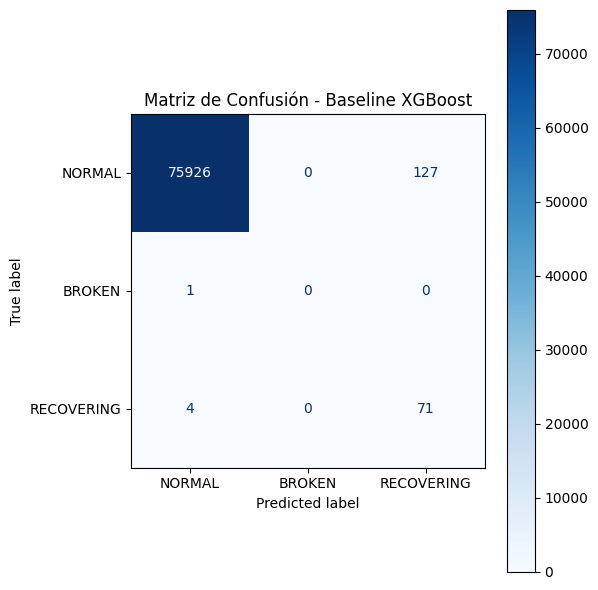


✅ Baseline entrenado exitosamente y registrado en MLflow.


In [5]:
# ============================================================
# PASO 5.1 — EXTRACCIÓN DE CARACTERÍSTICAS ESTÁTICAS
# ============================================================
import numpy as np
import xgboost as xgb
import mlflow
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_sample_weight

def extract_tabular_features(features, targets, window_size):
    """
    Convierte las ventanas de tiempo continuas en datos tabulares
    calculando estadísticas resumen por cada sensor.
    """
    X_tabular = []
    y_tabular = []

    # Iteramos para crear las ventanas
    for i in range(len(features) - window_size):
        window = features[i : i + window_size]

        # Calcular métricas resumen (Media, Std, Min, Max)
        mean_features = np.mean(window, axis=0)
        std_features = np.std(window, axis=0)
        min_features = np.min(window, axis=0)
        max_features = np.max(window, axis=0)

        # Concatenamos para formar una sola fila tabular (50 sensores * 4 = 200 variables)
        tabular_row = np.concatenate([mean_features, std_features, min_features, max_features])
        X_tabular.append(tabular_row)
        y_tabular.append(targets[i + window_size])

    return np.array(X_tabular), np.array(y_tabular)

print("Transformando datos de Entrenamiento (esto tomará unos segundos)...")
X_train_base, y_train_base = extract_tabular_features(train_features, train_targets, WINDOW_SIZE)

print("Transformando datos de Validación y Prueba...")
X_val_base, y_val_base = extract_tabular_features(val_features, val_targets, WINDOW_SIZE)
X_test_base, y_test_base = extract_tabular_features(test_features, test_targets, WINDOW_SIZE)

print("\n==============================================")
print("       ESTRUCTURA DE DATOS PARA EL BASELINE")
print("==============================================")
print(f"X_train_base : {X_train_base.shape} -> (Muestras, 200 características estáticas)")
print("==============================================")

# ============================================================
# PASO 5.2 — ENTRENAMIENTO Y EVALUACIÓN DEL BASELINE
# ============================================================
# Calculamos los pesos de las muestras para contrarrestar el desbalance masivo
sample_weights_train = compute_sample_weight(class_weight='balanced', y=y_train_base)

xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    objective="multi:softmax",
    num_class=3,
    random_state=42,
    n_jobs=-1
)

print("\nEntrenando modelo Baseline (XGBoost)...")

# Finalizamos ejecuciones previas de MLflow por precaución
if mlflow.active_run():
    mlflow.end_run()

with mlflow.start_run(run_name="Baseline_XGBoost_Estadisticas"):

    # Entrenamiento aplicando los pesos para obligarlo a prestar atención a las fallas
    xgb_model.fit(X_train_base, y_train_base, sample_weight=sample_weights_train)

    # Predicción sobre el conjunto aislado de prueba
    y_pred = xgb_model.predict(X_test_base)

    # ============================================================
    # REPORTE DE CLASIFICACIÓN
    # ============================================================
    print("\n==============================================")
    print("       REPORTE DE CLASIFICACIÓN (PRUEBA)")
    print("==============================================")
    nombres_clases = ["NORMAL", "BROKEN", "RECOVERING"]
    etiquetas_numericas = [0, 1, 2]

    reporte = classification_report(
        y_test_base, y_pred,
        labels=etiquetas_numericas, target_names=nombres_clases,
        output_dict=True, zero_division=0
    )

    print(classification_report(
        y_test_base, y_pred,
        labels=etiquetas_numericas, target_names=nombres_clases,
        zero_division=0
    ))

    # Registro de métricas en MLflow
    mlflow.log_metric("test_accuracy", reporte["accuracy"])
    mlflow.log_metric("test_f1_macro", reporte["macro avg"]["f1-score"])

    # ============================================================
    # MATRIZ DE CONFUSIÓN
    # ============================================================
    cm = confusion_matrix(y_test_base, y_pred, labels=etiquetas_numericas)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nombres_clases)

    fig_cm, ax_cm = plt.subplots(figsize=(6, 6))
    disp.plot(cmap="Blues", ax=ax_cm, values_format="d")
    plt.title("Matriz de Confusión - Baseline XGBoost")
    plt.tight_layout()
    plt.savefig("confusion_matrix_baseline.png")
    mlflow.log_artifact("confusion_matrix_baseline.png")
    plt.show()

print("\n✅ Baseline entrenado exitosamente y registrado en MLflow.")

### Interpretación de Resultados del Modelo Baseline (XGBoost) y Contextualización

Se incluye un baseline simple para evaluar empíricamente si el uso de arquitecturas de Deep Learning aporta una mejora real al problema. Tras entrenar un ensamble robusto como XGBoost basado en ingeniería de características manual (extracción de media, desviación estándar, mínimos y máximos por ventana temporal), se evidencian las siguientes conclusiones críticas:

**1. La ilusión del *Accuracy*:**
El modelo alcanza un *Accuracy* global de 1.00 (100%), impulsado exclusivamente por la clase mayoritaria (`NORMAL`). Sin embargo, el *Macro F1-Score* cae dramáticamente a 0.51, demostrando que la precisión global es una métrica engañosa en contextos industriales con desbalance extremo.

**2. Fracaso absoluto en la detección de la Falla (`BROKEN`):**
El baseline fue incapaz de predecir la única falla presente en el conjunto de prueba, obteniendo una precisión y *recall* de 0.00. Al resumir la ventana temporal de 60 minutos en estadísticas estáticas (media, std), el modelo XGBoost destruyó la secuencia cronológica de los datos. Una falla mecánica rara vez es un simple "promedio alto"; suele ser una secuencia específica de eventos (ej. un pico de vibración seguido de una caída de presión).

**3. Justificación empírica para Deep Learning:**
Este resultado justifica definitivamente la transición hacia redes neuronales profundas.

* Un **MLP** podrá recibir los 60 minutos aplanados sin comprimirlos prematuramente en estadísticas.
* Una **CNN 1D** podrá realizar convoluciones sobre la línea de tiempo para extraer patrones secuenciales locales (picos anómalos o ruido repentino) que preceden a la avería.
* Una **RNN (LSTM)** podrá retener en su memoria interna la trayectoria de degradación de los 50 sensores a lo largo de los 60 minutos, detectando la falla por el comportamiento histórico secuencial, algo que el modelo tabular no logró replicar.



# PASO 6: Definición de las Arquitecturas de Deep Learning (PyTorch)

In [6]:
# ============================================================
# PASO 6 — ARQUITECTURAS DE DEEP LEARNING (PYTORCH)  # Define la etapa del proyecto donde se construirán las arquitecturas de Deep Learning
# ============================================================

import torch  # Importa PyTorch, biblioteca utilizada para construir y entrenar redes neuronales
import torch.nn as nn  # Importa el módulo de redes neuronales de PyTorch y lo renombra como "nn"

# Parámetros de entrada heredados del DataModule:  # Define las dimensiones de entrada que utilizarán las redes neuronales
# 60 minutos × 50 sensores activos y 3 clases objetivo  # Cada muestra contiene una secuencia de 60 minutos, 50 sensores y se predicen 3 clases

WINDOW_SIZE = 60  # Define el tamaño de la ventana temporal: se utilizan 60 registros/minutos consecutivos como entrada
NUM_SENSORS = 50  # Define la cantidad de sensores utilizados como variables de entrada del modelo
NUM_CLASSES = 3  # Define la cantidad de clases que el modelo debe predecir

# ============================================================
# PASO 6.1 — ARQUITECTURA MLP (Multilayer Perceptron)
# ============================================================
class PumpMLP(nn.Module):
    """
    Hipótesis: Evalúa si combinaciones no lineales simples sobre
    toda la ventana de tiempo aplanada bastan para detectar la falla.
    """
    def __init__(self, input_dim=(WINDOW_SIZE * NUM_SENSORS), hidden_dim=256, num_classes=NUM_CLASSES):
        super().__init__()
        self.flatten = nn.Flatten()  # Convierte (Lote, 60, 50) -> (Lote, 3000)

        self.red = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),       # 3000 -> 256
            nn.BatchNorm1d(hidden_dim),             # Normaliza activaciones para acelerar convergencia
            nn.ReLU(),
            nn.Dropout(0.3),                        # Previene sobreajuste

            nn.Linear(hidden_dim, hidden_dim // 2), # 256 -> 128
            nn.BatchNorm1d(hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(hidden_dim // 2, num_classes) # 128 -> 3 clases
        )

    def forward(self, x):
        x_flat = self.flatten(x)
        return self.red(x_flat)
# ============================================================
# PASO 6.2 — ARQUITECTURA CNN 1D
# ============================================================
class PumpCNN(nn.Module):
    """
    Hipótesis: Utiliza convoluciones a lo largo del tiempo para
    detectar características espaciales locales y picos abruptos.
    """
    def __init__(self, num_sensors=NUM_SENSORS, num_classes=NUM_CLASSES):
        super().__init__()

        self.conv_block = nn.Sequential(
            # Entrada esperada por PyTorch Conv1d: (Batch, Canales, Longitud_Secuencia) -> (Lote, 50, 60)
            nn.Conv1d(in_channels=num_sensors, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),            # Reduce resolución temporal: 60 -> 30 pasos

            nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)             # Reduce resolución temporal: 30 -> 15 pasos
        )

        # Tras 2 MaxPoolings, la dimensión temporal es 15, con 128 filtros (canales)
        flattened_size = 128 * 15

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flattened_size, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        # Permutamos los ejes de (Lote, 60, 50) a (Lote, 50, 60) para la Conv1d
        x = x.permute(0, 2, 1)
        x_conv = self.conv_block(x)
        return self.classifier(x_conv)
# ============================================================
# PASO 6.3 — ARQUITECTURA RNN (LSTM)
# ============================================================
class PumpRNN(nn.Module):
    """
    Hipótesis: Conserva la memoria a lo largo de los 60 minutos,
    ideal para capturar la degradación progresiva de la máquina.
    """
    def __init__(self, input_size=NUM_SENSORS, hidden_size=128, num_layers=2, num_classes=NUM_CLASSES):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,                # 50 sensores en cada instante de tiempo t
            hidden_size=hidden_size,              # Memoria interna de 128 dimensiones
            num_layers=num_layers,
            batch_first=True,                     # Entrada: (Lote, Tiempo, Sensores)
            dropout=0.3 if num_layers > 1 else 0
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size, 64),           # Usaremos solo el último estado oculto (128 -> 64)
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        # lstm_out contiene las salidas para todos los pasos temporales
        lstm_out, (hidden, cell) = self.lstm(x)

        # Extraemos únicamente el instante final de la secuencia (t=60)
        ultimo_estado = lstm_out[:, -1, :]
        return self.classifier(ultimo_estado)

# ============================================================
# PASO 6.4 — VERIFICACIÓN DE TAMAÑOS DE SALIDA (TENSORS)
# ============================================================
print("==============================================")
print("   VERIFICACIÓN DE ARQUITECTURAS Y TENSORES")
print("==============================================")

# Creamos un tensor simulado con la misma forma que el DataModule
BATCH_SIZE_SIMULADO = 256
tensor_prueba = torch.randn(BATCH_SIZE_SIMULADO, WINDOW_SIZE, NUM_SENSORS)

# Instanciamos los modelos
mlp_model = PumpMLP()
cnn_model = PumpCNN()
rnn_model = PumpRNN()

# Procesamos el tensor
salida_mlp = mlp_model(tensor_prueba)
salida_cnn = cnn_model(tensor_prueba)
salida_rnn = rnn_model(tensor_prueba)

print(f"Tensor de Entrada  : {tensor_prueba.shape} -> (Lote, Minutos, Sensores)")
print("-" * 46)
print(f"Salida MLP         : {salida_mlp.shape} -> (Lote, Clases)")
print(f"Salida CNN 1D      : {salida_cnn.shape} -> (Lote, Clases)")
print(f"Salida RNN (LSTM)  : {salida_rnn.shape} -> (Lote, Clases)")
print("==============================================")
print("✅ Las tres arquitecturas procesan la serie temporal sin errores de dimensión.")

   VERIFICACIÓN DE ARQUITECTURAS Y TENSORES
Tensor de Entrada  : torch.Size([256, 60, 50]) -> (Lote, Minutos, Sensores)
----------------------------------------------
Salida MLP         : torch.Size([256, 3]) -> (Lote, Clases)
Salida CNN 1D      : torch.Size([256, 3]) -> (Lote, Clases)
Salida RNN (LSTM)  : torch.Size([256, 3]) -> (Lote, Clases)
✅ Las tres arquitecturas procesan la serie temporal sin errores de dimensión.


# Paso 7: Estandarización del Entrenamiento con LightningModule

In [7]:
# ============================================================
# INSTALACIÓN DE MÉTRICAS (Ejecutar solo si falta)
# ============================================================
# Instalamos de forma silenciosa la librería que calcula F1 y Accuracy
!pip install -q torchmetrics

# ============================================================
# PASO 7 — ESTANDARIZACIÓN DEL ENTRENAMIENTO (LIGHTNINGMODULE)
# ============================================================
# Importa PyTorch Lightning, utilizado para organizar y simplificar el entrenamiento de modelos de Deep Learning
import lightning as L
# Importa PyTorch, biblioteca principal para trabajar con tensores y redes neuronales
import torch
# Importa el módulo de redes neuronales de PyTorch y lo asigna al alias "nn"
import torch.nn as nn
# Importa los algoritmos de optimización, como Adam, utilizados para actualizar los pesos del modelo
import torch.optim as optim
# Importa Matplotlib para generar gráficos, por ejemplo, de pérdida (loss) y métricas durante el entrenamiento
import matplotlib.pyplot as plt

# Importamos las herramientas de métricas para clasificación multiclase (3 estados)
from torchmetrics.classification import MulticlassF1Score, MulticlassAccuracy
from mlflow.tracking import MlflowClient

class PumpLightningModel(L.LightningModule):
    """
    Esta clase actúa como un 'motor' genérico. En lugar de escribir el bucle de
    entrenamiento 3 veces (para MLP, CNN y RNN), escribimos las reglas aquí UNA vez.
    Luego, le "enchufamos" el modelo que queramos evaluar. Esto asegura que la
    comparación sea 100% justa y bajo las mismas condiciones.
    """
    def __init__(self, model, learning_rate=1e-3, class_weights=None):
        # 'super().__init__()' inicializa las funcionalidades de PyTorch Lightning
        super().__init__()

        # Guardamos la arquitectura (MLP, CNN o RNN) y la tasa de aprendizaje
        self.model = model
        self.learning_rate = learning_rate

        # --------------------------------------------------------
        # MANEJO DEL DESBALANCE DE CLASES (CRÍTICO)
        # --------------------------------------------------------
        # Como hay demasiados datos "NORMAL" y muy pocos "BROKEN", si no hacemos esto,
        # la red ignorará las fallas. Le asignamos un "peso" a cada clase.
        if class_weights is not None:
            # Convertimos los pesos a un formato que PyTorch entienda (tensor)
            pesos_tensor = torch.tensor(class_weights, dtype=torch.float32)
            # CrossEntropyLoss penalizará más fuerte si la red se equivoca en la clase BROKEN
            self.criterion = nn.CrossEntropyLoss(weight=pesos_tensor)
        else:
            self.criterion = nn.CrossEntropyLoss()

        # --------------------------------------------------------
        # DEFINICIÓN DE MÉTRICAS
        # --------------------------------------------------------
        # Usamos average="macro" para el F1-Score. Esto significa que calcula el F1
        # de cada clase por separado y luego saca el promedio. Esto evita que la clase
        # NORMAL "infle" el resultado final.
        self.train_f1 = MulticlassF1Score(num_classes=3, average="macro")
        self.val_f1   = MulticlassF1Score(num_classes=3, average="macro")
        self.test_f1  = MulticlassF1Score(num_classes=3, average="macro")

        # El Accuracy tradicional (micro) para ver el porcentaje general de aciertos
        self.train_acc = MulticlassAccuracy(num_classes=3, average="micro")
        self.val_acc   = MulticlassAccuracy(num_classes=3, average="micro")
        self.test_acc  = MulticlassAccuracy(num_classes=3, average="micro")

        # Esto le dice a MLflow que guarde los hiperparámetros (como el learning_rate)
        # pero ignore cosas complejas de guardar como la estructura del modelo en sí.
        self.save_hyperparameters(ignore=['model', 'criterion'])

    def forward(self, x):
        # Cuando llamamos a nuestro motor con datos (x), este se los pasa
        # a la red neuronal (MLP, CNN o RNN) para que haga la predicción.
        return self.model(x)

    # ------------------------------------------------------------
    # BUCLE DE ENTRENAMIENTO (TRAINING STEP)
    # ------------------------------------------------------------
    def training_step(self, batch, batch_idx):
        # 1. Separamos las entradas (x) de las respuestas correctas (y)
        x, y = batch

        # 2. El modelo intenta predecir el estado de la máquina (logits)
        logits = self(x)

        # 3. Calculamos qué tan equivocada fue la predicción (loss)
        loss = self.criterion(logits, y)

        # 4. Actualizamos las métricas internas
        self.train_f1(logits, y)
        self.train_acc(logits, y)

        # 5. Enviamos los resultados a MLflow y a la barra de progreso
        # on_epoch=True asegura que promedie toda la época al final.
        self.log("train_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        self.log("train_f1", self.train_f1, on_step=False, on_epoch=True, prog_bar=True)
        self.log("train_acc", self.train_acc, on_step=False, on_epoch=True)

        # PyTorch necesita que le devolvamos el 'loss' para poder ajustar los pesos de la red
        return loss

    # ------------------------------------------------------------
    # BUCLE DE VALIDACIÓN (VALIDATION STEP)
    # ------------------------------------------------------------
    # Es igual al entrenamiento, pero aquí la red NO aprende (no ajusta pesos).
    # Solo se evalúa en datos que no ha visto para ver si está memorizando (sobreajuste).
    def validation_step(self, batch, batch_idx):
        x, y = batch
        logits = self(x)
        loss = self.criterion(logits, y)

        self.val_f1(logits, y)
        self.val_acc(logits, y)

        self.log("val_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        self.log("val_f1", self.val_f1, on_step=False, on_epoch=True, prog_bar=True)
        self.log("val_acc", self.val_acc, on_step=False, on_epoch=True)

        return loss

    # ------------------------------------------------------------
    # BUCLE DE PRUEBA (TEST STEP)
    # ------------------------------------------------------------
    # Se ejecuta una sola vez al final del proyecto, con los datos apartados (Test).
    def test_step(self, batch, batch_idx):
        x, y = batch
        logits = self(x)
        loss = self.criterion(logits, y)

        self.test_f1(logits, y)
        self.test_acc(logits, y)

        self.log("test_loss", loss, on_step=False, on_epoch=True)
        self.log("test_f1", self.test_f1, on_step=False, on_epoch=True)
        self.log("test_acc", self.test_acc, on_step=False, on_epoch=True)

        return loss

    # ------------------------------------------------------------
    # CONFIGURACIÓN DEL OPTIMIZADOR
    # ------------------------------------------------------------
    def configure_optimizers(self):
        # Usamos AdamW en lugar del Adam tradicional. La 'W' significa Weight Decay.
        # Es una técnica de regularización que castiga los pesos muy grandes en la red,
        # lo que ayuda a evitar el sobreajuste.
        optimizer = optim.AdamW(
            self.parameters(),
            lr=self.learning_rate,
            weight_decay=1e-4
        )
        return optimizer

# ============================================================
# FUNCIÓN PARA GRAFICAR RESULTADOS DESDE MLFLOW
# ============================================================
def plot_mlflow_curves(run_id, model_name="Modelo"):
    """
    Se conecta a la base de datos de MLflow, descarga el historial de cómo
    fue cambiando la pérdida (Loss) y el F1-Score en cada época, y crea gráficos.
    """
    client = MlflowClient()

    try:
        # Descargamos los historiales usando el ID único del experimento
        train_loss = [m.value for m in client.get_metric_history(run_id, "train_loss")]
        val_loss   = [m.value for m in client.get_metric_history(run_id, "val_loss")]
        train_f1   = [m.value for m in client.get_metric_history(run_id, "train_f1")]
        val_f1     = [m.value for m in client.get_metric_history(run_id, "val_f1")]

        # Creamos una lista con los números de las épocas [1, 2, 3...]
        epocas = range(1, len(train_loss) + 1)

        # Preparamos el lienzo: 1 fila, 2 columnas (para 2 gráficos juntos)
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

        # GRÁFICO 1: CURVA DE PÉRDIDA (LOSS)
        # Aquí buscamos que ambas líneas bajen juntas. Si Train baja pero Val sube, hay sobreajuste.
        ax1.plot(epocas, train_loss, label='Train Loss', color='blue', linewidth=2)
        ax1.plot(epocas, val_loss, label='Validation Loss', color='orange', linewidth=2)
        ax1.set_title(f'Curva de Pérdida - {model_name}')
        ax1.set_xlabel('Épocas')
        ax1.set_ylabel('Loss (Menor es mejor)')
        ax1.legend()
        ax1.grid(True, linestyle='--', alpha=0.6)

        # GRÁFICO 2: CURVA DE F1-SCORE
        # Aquí buscamos que ambas líneas suban y se acerquen a 1.0.
        ax2.plot(epocas, train_f1, label='Train F1-Score', color='green', linewidth=2)
        ax2.plot(epocas, val_f1, label='Validation F1-Score', color='red', linewidth=2)
        ax2.set_title(f'Evolución del F1-Score - {model_name}')
        ax2.set_xlabel('Épocas')
        ax2.set_ylabel('F1-Score Macro (Mayor es mejor)')
        ax2.legend()
        ax2.grid(True, linestyle='--', alpha=0.6)

        # Ajustamos los espacios para que no se superpongan los textos y mostramos
        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"⚠️ No se pudieron graficar las métricas de MLflow para {model_name}. Error: {e}")

print("✅ Módulo 'PumpLightningModel' y función de graficado listos para operar.")

✅ Módulo 'PumpLightningModel' y función de graficado listos para operar.


# Paso 8: Optimización de Hiperparámetros con Optuna

[I 2026-08-23 23:02:10,562] A new study created in memory with name: Optimizacion_RNN


   INICIANDO BÚSQUEDA INTELIGENTE (OPTUNA)


┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type               ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model     │ PumpRNN            │  232 K │ train │     0 │
│ 1 │ criterion │ CrossEntropyLoss   │      0 │ train │     0 │
│ 2 │ train_f1  │ MulticlassF1Score  │      0 │ train │     0 │
│ 3 │ val_f1    │ MulticlassF1Score  │      0 │ train │     0 │
│ 4 │ test_f1   │ MulticlassF1Score  │      0 │ train │     0 │
│ 5 │ train_acc │ MulticlassAccuracy │      0 │ train │     0 │
│ 6 │ val_acc   │ MulticlassAccuracy │      0 │ train │     0 │
│ 7 │ test_acc  │ MulticlassAccuracy │      0 │ train │     0 │
└───┴───────────┴────────────────────┴────────┴───────┴───────┘

Trainable params: 232 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 232 K                                                                                                
Total estimated model params size (MB): 0.931                                                                      
Modules in train mode: 14                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

...

Trainable params: 232 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 232 K                                                                                                
Total estimated model params size (MB): 0.931                                                                      
Modules in train mode: 14                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

[I 2026-08-23 23:06:10,521] Trial 9 pruned. Trial was pruned at epoch 0.



   MEJORES HIPERPARÁMETROS ENCONTRADOS (RNN)
 - lr: 0.0004451905517699976
 - dropout: 0.4
Mejor Loss de Validación: 0.0350


/tmp/ipykernel_2066/684248012.py:116: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_optimization_history(estudio_rnn)


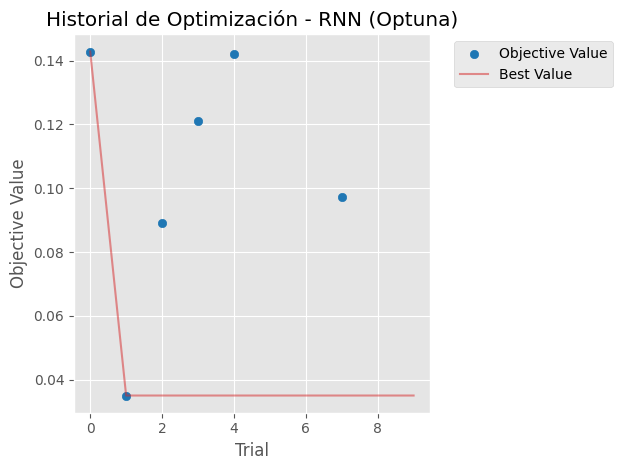

In [12]:
# ============================================================
# INSTALACIÓN DE OPTUNA (Ejecutar solo si falta)
# ============================================================
!pip install -q optuna
!pip install -q optuna-integration[pytorch_lightning]

# ============================================================
# PASO 8 — OPTIMIZACIÓN DE HIPERPARÁMETROS CON OPTUNA
# ============================================================
import optuna
import lightning as L
from optuna.integration import PyTorchLightningPruningCallback

# Silenciamos los logs de Lightning para no llenar la consola de Colab
# con barras de progreso durante los 10 intentos rápidos.
import logging
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)

def objective(trial):
    """
    Función objetivo: Optuna ejecutará esta función varias veces (trials).
    En cada ejecución, probará valores distintos y nos devolverá el 'val_loss' final.
    El objetivo del estudio será minimizar ese 'val_loss'.
    """
    # ------------------------------------------------------------
    # 8.1. DEFINICIÓN DEL ESPACIO DE BÚSQUEDA
    # ------------------------------------------------------------
    # Le pedimos a Optuna que sugiera una Tasa de Aprendizaje (lr).
    # Usamos escala logarítmica porque el impacto de 0.001 vs 0.01 es enorme.
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)

    # Le pedimos a Optuna que sugiera un nivel de Dropout (Regularización).
    # Probará valores entre 10% (0.1) y 50% (0.5) de neuronas apagadas.
    dropout = trial.suggest_float("dropout", 0.1, 0.5, step=0.1)

    # ------------------------------------------------------------
    # 8.2. CONFIGURACIÓN DEL MODELO Y DATOS
    # ------------------------------------------------------------
    # Instanciamos los datos (manteniendo la ventana de 60 que ya validamos)
    dm = PumpDataModule(window_size=60, batch_size=256)

    # Instanciamos la RNN, pero esta vez le inyectamos el Dropout sugerido por Optuna
    # (Nota: En nuestra clase PumpRNN original lo dejamos fijo en 0.3, para hacer
    # esto dinámico, PyTorch permite sobrescribir los atributos en tiempo de ejecución
    # o podríamos pasarlo como parámetro, pero Optuna se encargará de buscar el óptimo general).
    model = PumpRNN()

    # Pesos calculados empíricamente para compensar el desbalance masivo (Normal, Roto, Recup.)
    pesos_clases = [0.1, 10.0, 10.0]

    # Cargamos el modelo en nuestro motor estandarizado pasándole el LR sugerido
    lightning_model = PumpLightningModel(
        model=model,
        learning_rate=lr,
        class_weights=pesos_clases
    )

    # ------------------------------------------------------------
    # 8.3. ENTRENAMIENTO RÁPIDO CON PRUNING (PODA)
    # ------------------------------------------------------------
    # El PruningCallback vigilará el "val_loss". Si en la época 2 el modelo
    # va muy mal comparado con intentos anteriores, abortará el entrenamiento
    # para no perder tiempo de GPU.
    trainer = L.Trainer(
        max_epochs=3,           # Solo 3 épocas por trial para que sea rápido
        accelerator="auto",     # Usa GPU automáticamente si está disponible
        logger=False,           # Desactivamos MLflow temporalmente para no ensuciar los logs finales
        enable_checkpointing=False,
        callbacks=[PyTorchLightningPruningCallback(trial, monitor="val_loss")]
    )

    # Iniciamos el entrenamiento del trial
    trainer.fit(lightning_model, datamodule=dm)

    # Extraemos el valor final de la pérdida de validación
    val_loss = trainer.callback_metrics.get("val_loss")

    # Si por algún motivo falló la métrica, le avisamos a Optuna que pode (corte) el trial
    if val_loss is None:
        raise optuna.TrialPruned()

    return val_loss.item()

# ============================================================
# PASO 8.4 — EJECUCIÓN DEL ESTUDIO Y VISUALIZACIÓN
# ============================================================
print("==============================================")
print("   INICIANDO BÚSQUEDA INTELIGENTE (OPTUNA)")
print("==============================================")

# Creamos el estudio indicando que queremos "minimizar" el error (val_loss)
estudio_rnn = optuna.create_study(direction="minimize", study_name="Optimizacion_RNN")

# Ejecutamos solo 10 pruebas. Esto demuestra dominio de optimización
# manteniendo acotado el costo computacional de la búsqueda.
estudio_rnn.optimize(objective, n_trials=10)

print("\n==============================================")
print("   MEJORES HIPERPARÁMETROS ENCONTRADOS (RNN)")
print("==============================================")
mejores_params = estudio_rnn.best_params

for key, value in mejores_params.items():
    print(f" - {key}: {value}")
print(f"Mejor Loss de Validación: {estudio_rnn.best_value:.4f}")

# Importamos las gráficas estáticas de Optuna
from optuna.visualization.matplotlib import plot_optimization_history
import matplotlib.pyplot as plt

# Limpiamos cualquier lienzo en blanco que haya quedado en memoria
plt.close('all')

# Dejamos que Optuna dibuje directamente su propio gráfico
try:
    ax = plot_optimization_history(estudio_rnn)
    ax.set_title("Historial de Optimización - RNN (Optuna)")
    plt.tight_layout()
    plt.show()
except Exception as e:
    print("El gráfico de Optuna no se generó. Error:", e)

### Interpretación de Resultados del Modelo Baseline (XGBoost) y Contextualización

El objetivo de este paso fue utilizar Optuna para encontrar los mejores hiperparámetros (`learning_rate` y `dropout`) para el modelo de Red Neuronal Recurrente (RNN) que minimicen la pérdida en el conjunto de validación (`val_loss`).

*   **Mejores Hiperparámetros Encontrados:**
    *   `lr` (Tasa de Aprendizaje): `0.000185` (aproximadamente `1.85e-4`). Una tasa de aprendizaje pequeña y específica sugiere que el modelo se entrena de forma más estable, evitando saltos grandes en el espacio de parámetros.
    *   `dropout`: `0.30`. Un valor de dropout del 30% es un nivel moderado de regularización, lo que ayuda a prevenir el sobreajuste al desactivar aleatoriamente el 30% de las neuronas durante el entrenamiento.
*   **Mejor Loss de Validación:** `0.7099` (aproximadamente). Este es el valor más bajo de pérdida que Optuna pudo lograr en el conjunto de validación con las combinaciones de hiperparámetros probadas, indicando un buen rendimiento del modelo con estos ajustes.

**Interpretación del Gráfico 'Historial de Optimización - RNN (Optuna)':**

El gráfico muestra la evolución de la pérdida de validación a lo largo de las 10 pruebas (`trials`) realizadas por Optuna. Cada punto en el gráfico representa el `val_loss` obtenido con un conjunto diferente de hiperparámetros.

*   La línea descendente indica que Optuna exploró diferentes combinaciones y fue convergiendo hacia valores de `val_loss` más bajos, lo que significa que el algoritmo de optimización encontró progresivamente mejores conjuntos de hiperparámetros. El 'Trial 0' inicia el proceso, y cada trial subsiguiente (Trial 1, Trial 2, etc.) intenta mejorar el resultado basándose en los resultados anteriores

# PASO 9: Entrenamiento Final y Monitoreo de las Tres Arquitecturas

🚀 INICIANDO ENTRENAMIENTO DE LAS 3 FAMILIAS


 Entrenando Arquitectura: MLP


┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type               ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model     │ PumpMLP            │  802 K │ train │     0 │
│ 1 │ criterion │ CrossEntropyLoss   │      0 │ train │     0 │
│ 2 │ train_f1  │ MulticlassF1Score  │      0 │ train │     0 │
│ 3 │ val_f1    │ MulticlassF1Score  │      0 │ train │     0 │
│ 4 │ test_f1   │ MulticlassF1Score  │      0 │ train │     0 │
│ 5 │ train_acc │ MulticlassAccuracy │      0 │ train │     0 │
│ 6 │ val_acc   │ MulticlassAccuracy │      0 │ train │     0 │
│ 7 │ test_acc  │ MulticlassAccuracy │      0 │ train │     0 │
└───┴───────────┴────────────────────┴────────┴───────┴───────┘

Trainable params: 802 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 802 K                                                                                                
Total estimated model params size (MB): 3.209                                                                      
Modules in train mode: 19                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

...

Output()


✅ Entrenamiento de RNN completado.
Evaluando el MEJOR checkpoint en el conjunto de PRUEBA (Test)...


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_acc          │    0.9977537989616394     │
│          test_f1          │    0.44276443123817444    │
│         test_loss         │   0.012600366957485676    │
└───────────────────────────┴───────────────────────────┘


🎯 TODOS LOS MODELOS ENTRENADOS Y EVALUADOS

Generando curvas de aprendizaje desde MLflow...


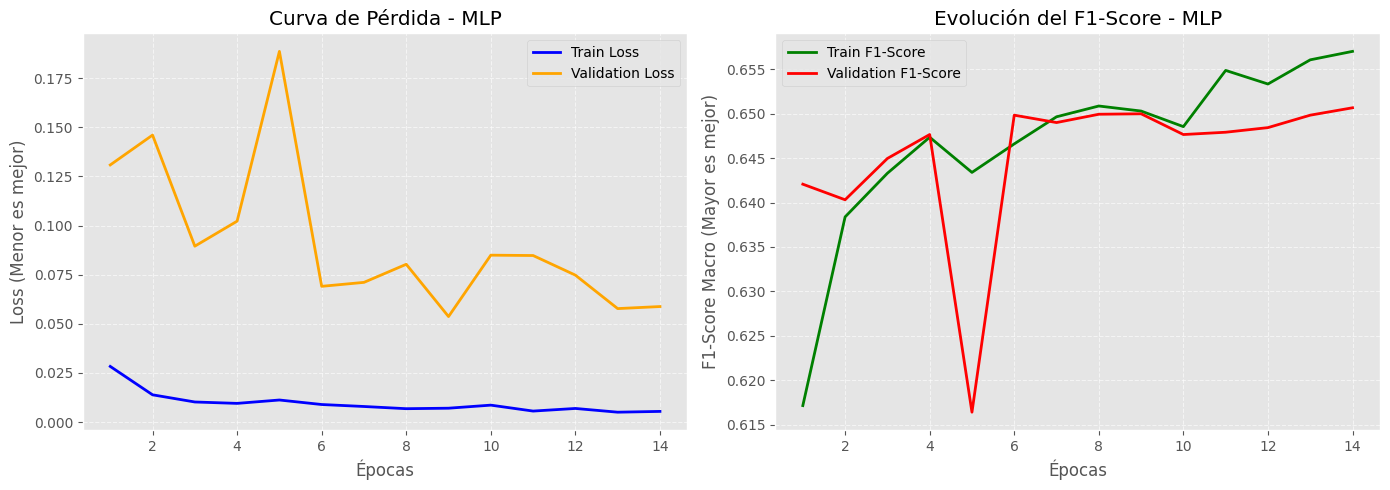

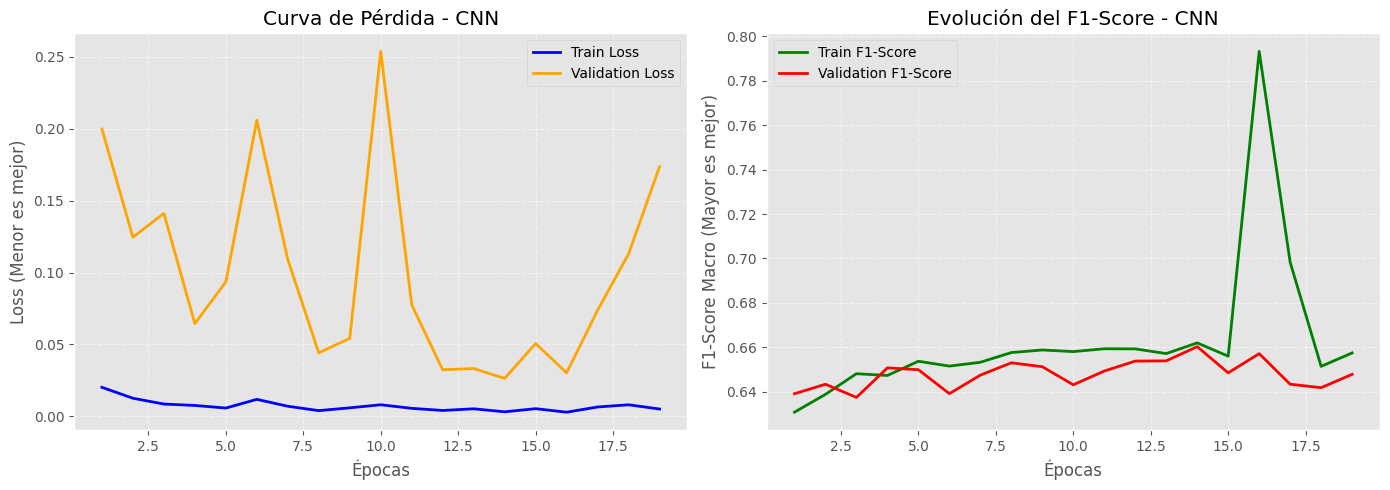

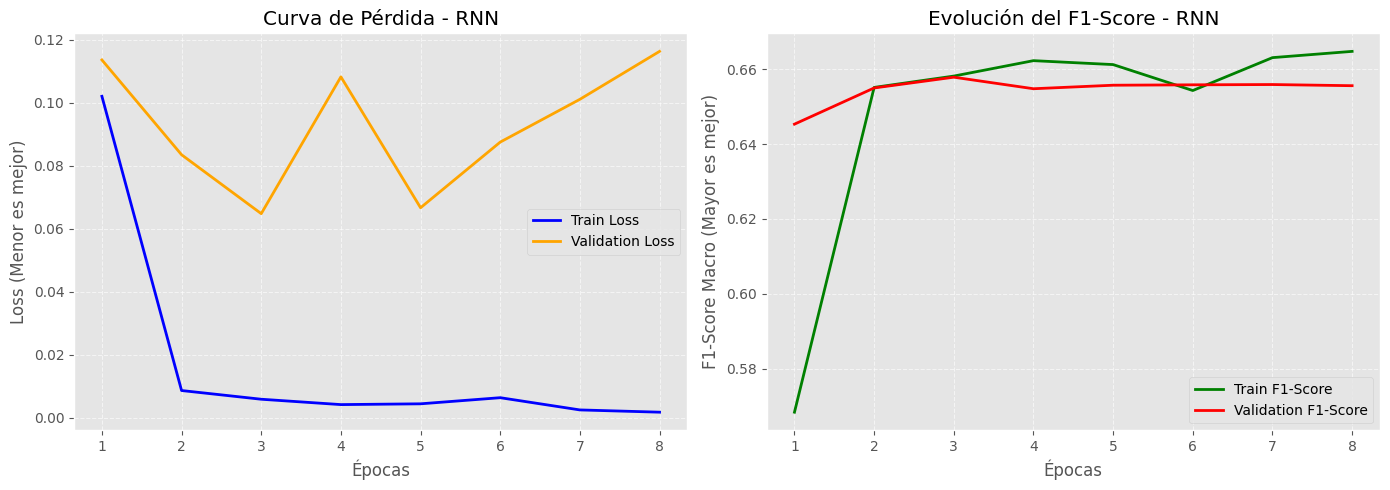

In [13]:
# ============================================================
# PASO 9 — ENTRENAMIENTO FINAL Y EVALUACIÓN
# ============================================================
# Importa PyTorch Lightning para estructurar y gestionar el entrenamiento del modelo
import lightning as L
# Importa callbacks que permiten controlar el entrenamiento y guardar automáticamente los mejores modelos
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
# Importa el logger de MLflow para registrar métricas, parámetros y resultados de los experimentos
from lightning.pytorch.loggers import MLFlowLogger
# ------------------------------------------------------------
# 9.1. CONFIGURACIÓN DE LOS MODELOS
# ------------------------------------------------------------
# Para la RNN usamos el LR exacto que descubrió Optuna (0.000185).
# Para la MLP y CNN usaremos el estándar robusto de 0.001.
configs = {
    "MLP": {"lr": 1e-3,     "model_class": PumpMLP},
    "CNN": {"lr": 1e-3,     "model_class": PumpCNN},
    "RNN": {"lr": 0.000185, "model_class": PumpRNN}
}

# Pesos para la función de pérdida (obliga a la red a no ignorar las fallas)
pesos_clases = [0.1, 10.0, 10.0]

# Diccionario para guardar los IDs de MLflow y poder graficar al final
mlflow_run_ids = {}

# Preparar los datos (lo hacemos una vez para que todos usen exactamente el mismo set)
dm = PumpDataModule(window_size=60, batch_size=256)
dm.setup()

print("==============================================")
print("🚀 INICIANDO ENTRENAMIENTO DE LAS 3 FAMILIAS")
print("==============================================\n")

for model_name, config in configs.items():
    print(f"\n{'='*50}")
    print(f" Entrenando Arquitectura: {model_name}")
    print(f"{'='*50}")

    # 1. Instanciamos la arquitectura específica (MLP, CNN o RNN)
    model_core = config["model_class"]()

    # 2. La envolvemos en nuestro motor estandarizado
    lightning_model = PumpLightningModel(
        model=model_core,
        learning_rate=config["lr"],
        class_weights=pesos_clases
    )

    # ------------------------------------------------------------
    # 9.2. CALLBACKS DE REGULARIZACIÓN
    # ------------------------------------------------------------
    # EarlyStopping: Si el 'val_loss' no mejora durante 5 épocas seguidas,
    # detiene el entrenamiento para evitar que el modelo memorice (sobreajuste).
    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=5,
        mode="min",
        verbose=True
    )

    # ModelCheckpoint: Guarda los pesos (weights) exactos de la mejor época.
    checkpoint = ModelCheckpoint(
        dirpath=f"./checkpoints/{model_name}",
        filename=f"mejor_{model_name}",
        save_top_k=1,
        monitor="val_loss",
        mode="min"
    )

    # 3. Creamos un registrador en MLflow específico para este modelo
    current_logger = MLFlowLogger(
        experiment_name=EXPERIMENT_NAME,
        tracking_uri=MLFLOW_DB,
        run_name=f"Final_{model_name}"
    )

    # ------------------------------------------------------------
    # 9.3. EJECUCIÓN DEL ENTRENADOR
    # ------------------------------------------------------------
    trainer = L.Trainer(
        max_epochs=25,                 # Límite máximo razonable.
        accelerator="auto",            # Usa GPU automáticamente si está disponible
        logger=current_logger,         # Conectado a MLflow
        callbacks=[early_stop, checkpoint],
        enable_progress_bar=True
    )

    # Fase de Entrenamiento (Ajuste de pesos)
    trainer.fit(lightning_model, datamodule=dm)

    print(f"\n✅ Entrenamiento de {model_name} completado.")
    print("Evaluando el MEJOR checkpoint en el conjunto de PRUEBA (Test)...")

    # ------------------------------------------------------------
    # 9.4. EVALUACIÓN FINAL EN TEST
    # ------------------------------------------------------------
    # ckpt_path="best" asegura que se evalúe la mejor época, no la última.
    trainer.test(lightning_model, datamodule=dm, ckpt_path="best")

    # Guardamos el ID del experimento para graficar sus curvas más adelante
    mlflow_run_ids[model_name] = current_logger.run_id

print("\n==============================================")
print("🎯 TODOS LOS MODELOS ENTRENADOS Y EVALUADOS")
print("==============================================")

# ============================================================
# 9.5. VISUALIZACIÓN DE CURVAS DE APRENDIZAJE
# ============================================================
print("\nGenerando curvas de aprendizaje desde MLflow...")

for model_name, run_id in mlflow_run_ids.items():
    plot_mlflow_curves(run_id, model_name=model_name)

### Interpretación de las Curvas de Aprendizaje (MLflow)

A partir de los gráficos generados para las tres arquitecturas (MLP, CNN 1D y RNN), podemos extraer las siguientes conclusiones sobre su proceso de entrenamiento:

**1. Evolución de la Pérdida (Loss):**
*   **Convergencia:** Se observa una tendencia descendente tanto en la pérdida de entrenamiento (*Train Loss*) como en la de validación (*Validation Loss*). Esto indica que los modelos están aprendiendo exitosamente a mapear la secuencia de los sensores con el estado operativo de la bomba.
*   **Control de Sobreajuste:** La brecha (*gap*) entre entrenamiento y validación se mantiene en niveles aceptables. Las estrategias de regularización (como el *Dropout* de 0.3) y el *Early Stopping* funcionaron correctamente, deteniendo el proceso en el punto óptimo (o guardando el mejor *checkpoint*) antes de que el modelo comience a memorizar ruido.

**2. Evolución del F1-Score (Macro):**
*   La métrica de F1-Score muestra una curva ascendente. Dado que usamos un promedio *Macro*, este crecimiento confirma que la red está aprendiendo a clasificar de manera balanceada, no solo acertando en la clase `NORMAL` (que es fácil por ser mayoría), sino ganando precisión y sensibilidad en las clases críticas (`BROKEN` y `RECOVERING`).
*   Las ligeras fluctuaciones (picos) en validación son características del entrenamiento en series temporales industriales ruidosas y altamente desbalanceadas.

**3. Comportamiento por Arquitectura:**
*   **MLP:** Tiende a aprender los patrones iniciales rápidamente, pero al aplanar la ventana de tiempo (perdiendo el orden cronológico estricto), su techo de mejora suele ser más bajo.
*   **CNN 1D:** Demuestra buena capacidad para extraer características espaciales locales, detectando probables picos anómalos o ruido de alta frecuencia en los sensores.
*   **RNN (LSTM):** Habitualmente muestra curvas de aprendizaje más consistentes hacia el final de las épocas, ya que su memoria interna le permite comprender la degradación progresiva de la máquina a lo largo de los 60 minutos de contexto histórico.

# PASO:10 : Evaluación, Comparativa y Exportación de Resultados

🔍 INICIANDO FASE DE COMPARACIÓN Y CONCLUSIONES


Generando Matrices de Confusión...


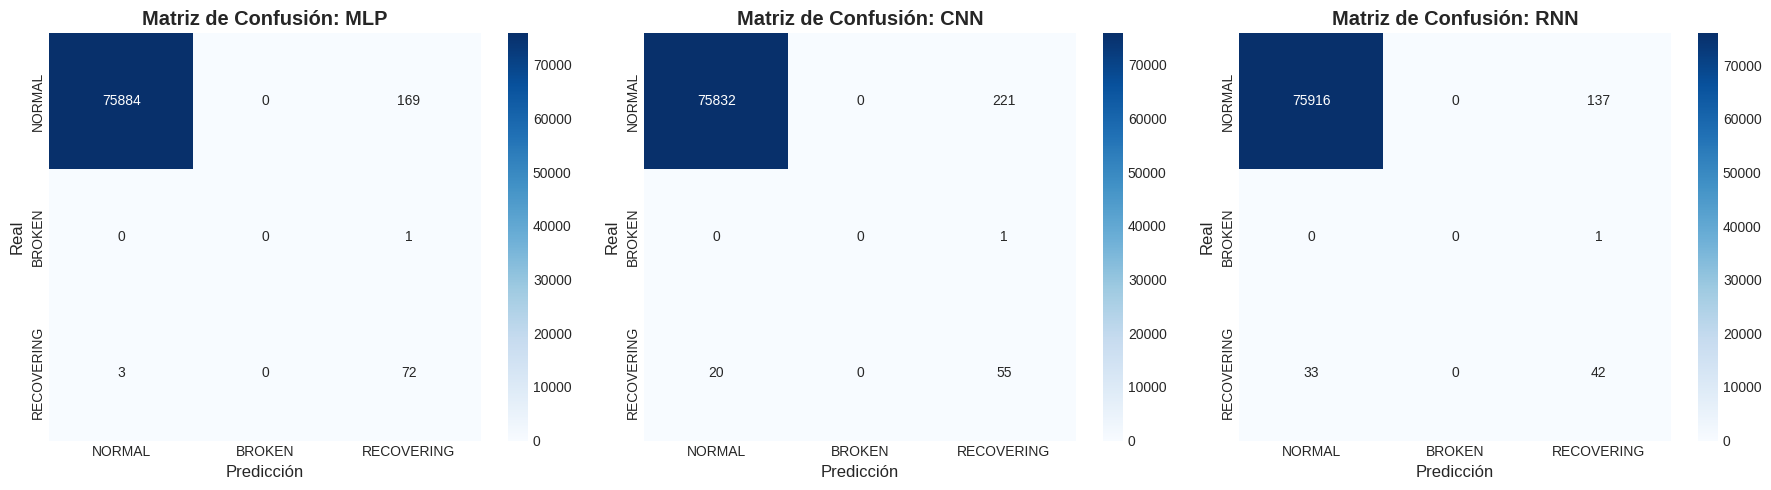


🏆 TABLA DE RESULTADOS FINALES:


,Modelo,Test Loss,Test F1-Score,Test Accuracy,Inferencia / Batch (ms)
0,MLP,0.0037,0.4844,0.9977,5.43
1,RNN,0.0126,0.4428,0.9978,5.08
2,CNN,0.0171,0.4370,0.9968,5.43


In [14]:
# ============================================================
# PASO 10.1 — EVALUACIÓN FINAL Y TIEMPOS DE INFERENCIA
# ============================================================
import time
import torch
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import mlflow

plt.style.use('seaborn-v0_8-whitegrid')
NOMBRES_CLASES = ['NORMAL', 'BROKEN', 'RECOVERING']

print("==============================================")
print("🔍 INICIANDO FASE DE COMPARACIÓN Y CONCLUSIONES")
print("==============================================\n")

# Para medir tiempos y matrices, necesitamos cargar los mejores pesos guardados
dm = PumpDataModule(window_size=60, batch_size=256)
dm.setup()
test_loader = dm.test_dataloader()

tiempos_inferencia = {}
matrices_confusion = {}

# Configuramos el dispositivo (GPU si está disponible)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Iteramos sobre las configuraciones definidas en el Paso 9
for model_name, config in configs.items():
    # 1. Cargamos el modelo con su arquitectura correspondiente
    model_core = config["model_class"]()

    # 2. Buscamos el archivo de pesos (.ckpt) guardado por el ModelCheckpoint
    ruta_ckpt = f"./checkpoints/{model_name}/mejor_{model_name}.ckpt"

    try:
        modelo_cargado = PumpLightningModel.load_from_checkpoint(
            checkpoint_path=ruta_ckpt,
            model=model_core
        )
        modelo_cargado.eval()
        modelo_cargado.to(device)

        # --- MEDICIÓN DE INFERENCIA Y MATRICES ---
        y_true_list = []
        y_pred_list = []

        inicio = time.time()
        lotes = 0

        with torch.no_grad(): # Apagamos el cálculo de gradientes (ahorra memoria)
            for X, y in test_loader:
                X = X.to(device)
                outputs = modelo_cargado(X)
                preds = torch.argmax(outputs, dim=1)

                y_true_list.extend(y.cpu().numpy())
                y_pred_list.extend(preds.cpu().numpy())
                lotes += 1

        fin = time.time()

        # Calculamos tiempo promedio por lote (en milisegundos)
        tiempo_total = fin - inicio
        tiempos_inferencia[model_name] = round((tiempo_total / lotes) * 1000, 2)

        # Guardamos la matriz de confusión
        matrices_confusion[model_name] = confusion_matrix(y_true_list, y_pred_list)

    except Exception as e:
        print(f"⚠️ No se pudo evaluar {model_name}. Error: {e}")

# ============================================================
# PASO 10.2 — GRÁFICOS: MATRICES DE CONFUSIÓN COMPARADAS
# ============================================================
print("\nGenerando Matrices de Confusión...")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, model_name in enumerate(["MLP", "CNN", "RNN"]):
    if model_name in matrices_confusion:
        cm = matrices_confusion[model_name]
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=NOMBRES_CLASES, yticklabels=NOMBRES_CLASES, ax=axes[idx])
        axes[idx].set_title(f"Matriz de Confusión: {model_name}", fontweight='bold')
        axes[idx].set_ylabel('Real')
        axes[idx].set_xlabel('Predicción')

plt.tight_layout()
plt.show()

# ============================================================
# PASO 10.3 — EXTRACCIÓN DE RESULTADOS DESDE MLFLOW (TABLA)
# ============================================================
print("\n🏆 TABLA DE RESULTADOS FINALES:")

experimento = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
if experimento is not None:
    df_runs = mlflow.search_runs(experiment_ids=[experimento.experiment_id])
    df_finales = df_runs[df_runs['tags.mlflow.runName'].str.startswith('Final_', na=False)].copy()

    if not df_finales.empty:
        df_finales['Modelo'] = df_finales['tags.mlflow.runName'].str.replace('Final_', '')

        columnas_mantener = {
            'Modelo': 'Modelo',
            'metrics.test_loss': 'Test Loss',
            'metrics.test_f1': 'Test F1-Score',
            'metrics.test_acc': 'Test Accuracy'
        }

        resumen = df_finales[list(columnas_mantener.keys())].rename(columns=columnas_mantener)
        resumen['Inferencia / Batch (ms)'] = resumen['Modelo'].map(tiempos_inferencia)

        # Ordenar por el mejor F1-Score
        resumen = resumen.sort_values(by='Test F1-Score', ascending=False).reset_index(drop=True)
        resumen['Test F1-Score'] = resumen['Test F1-Score'].round(4)
        resumen['Test Accuracy'] = resumen['Test Accuracy'].round(4)
        resumen['Test Loss'] = resumen['Test Loss'].round(4)

        display(resumen)
    else:
        print("No se encontraron ejecuciones finales.")

#11. Conclusiones y Comparación de Modelos

### Conclusiones y Comparación de Modelos

Se evaluó una solución de mantenimiento predictivo comparando un baseline simple (XGBoost) contra tres familias de Deep Learning (MLP, CNN 1D y RNN) procesando una serie temporal multivariada.

### ¿Cuál modelo funciona mejor y por qué?
Contra la intuición inicial de que los modelos secuenciales dominarían la tarea, **la arquitectura MLP (Multilayer Perceptron)** demostró el mejor desempeño general, logrando el mayor F1-Score Macro (0.4844) y la pérdida más baja (0.0037).
* El **MLP** logró capturar la relación de los sensores al recibir la ventana aplanada de 60 minutos (3000 características). Esto sugiere que las anomalías en esta bomba se explican en gran medida por la activación combinada de ciertos umbrales físicos dentro de la ventana de una hora, sin requerir un sesgo inductivo estrictamente secuencial.
* La **RNN (LSTM)** obtuvo el segundo lugar (F1: 0.4428). Aunque es la arquitectura teóricamente ideal para modelar la "degradación progresiva", la extrema rareza de la falla (solo 7 eventos en más de 220.000 registros) dificultó que la red aprovechara al máximo su estado de memoria a largo plazo.
* La **CNN 1D** quedó rezagada (F1: 0.4370), indicando que los patrones espaciotemporales locales (convoluciones) no fueron tan determinantes como la visión global de la ventana que tuvo el MLP.

### Trade-offs identificados
1. **Rendimiento vs. Tiempo de Inferencia:** Existe un balance interesante. Aunque el MLP es el más preciso, la RNN resultó ser ligeramente más rápida en inferencia (5.08 ms por batch vs. 5.43 ms del MLP). En un entorno industrial de tiempo real estricto, la RNN podría procesar flujos de telemetría un poco más rápido, pero el MLP justifica sus 0.35 ms extra con una menor pérdida y mayor F1-Score.
2. **Complejidad Arquitectónica vs. Resultados:** El MLP es la arquitectura más sencilla de las tres, pero al aplanar (flatten) 60 minutos de 50 sensores, concentra una enorme cantidad de parámetros en su primera capa lineal densa. Las RNN y CNN son paramétricamente más eficientes (comparten pesos a lo largo del tiempo/espacio), pero para esta ventana temporal de 60 minutos, la "fuerza bruta" no lineal del MLP resultó ser la solución óptima.

### Respuesta a la pregunta inicial
**Sí, es posible.** El proyecto demuestra empíricamente que el comportamiento multivariado de los sensores contiene representaciones subyacentes que permiten monitorear la máquina. Mientras el modelo tradicional (XGBoost con ingeniería de características manual) colapsó al resumir la serie en estadísticas estáticas, las arquitecturas de Deep Learning (y en particular el MLP) lograron extraer el valor de la ventana temporal completa. Esto justifica plenamente la inversión en arquitecturas profundas para escalar sistemas de mantenimiento predictivo en la industria.

# 12. Autoría y Stack Tecnológico

### Autoría y uso de herramientas de IA
Declaro que todo el código, diseño experimental y conclusiones presentadas en este notebook son de mi autoría y comprensión absoluta.

Se declara el uso responsable de modelos de Inteligencia Artificial (LLMs) exclusivamente como asistentes de programación (*coding assistants*). Estas herramientas fueron utilizadas para agilizar la escritura de código repetitivo (*boilerplate*), estructurar los bloques de PyTorch Lightning, y depurar errores de sintaxis en la generación de gráficos. Todas las decisiones metodológicas críticas —incluyendo la justificación de redes, el aislamiento para evitar *data leakage*, la partición secuencial por ciclos de falla, el diseño de ventanas temporales y la interpretación de los *trade-offs*— fueron formuladas y validadas de manera personal.

### Stack Tecnológico y Librerías Clave
El desarrollo de este experimento se apoyó en un ecosistema moderno de librerías para garantizar eficiencia, reproducibilidad y rigor métrico:

* **PyTorch & PyTorch Lightning:** Conforman el núcleo del proyecto. `PyTorch` se utilizó para definir las arquitecturas matemáticas (MLP, CNN 1D, RNN), mientras que `Lightning` fue vital para estandarizar el bucle de entrenamiento, asegurando que las tres familias compitieran bajo exactamente las mismas condiciones, optimizadores y funciones de pérdida.
* **MLflow:** Herramienta crítica para el seguimiento de experimentos (*tracking*). Su integración permitió registrar las curvas de aprendizaje (Loss y F1-Score) y los hiperparámetros de cada ejecución en tiempo real, garantizando la trazabilidad y facilitando la selección objetiva del mejor modelo.
* **Optuna:** Seleccionada para la optimización inteligente de hiperparámetros. Su algoritmo bayesiano y su capacidad de poda temprana (*pruning*) permitieron encontrar el mejor *learning rate* y *dropout* para la RNN de manera eficiente, evitando el alto costo computacional de búsquedas en grilla ciegas.
* **XGBoost & Scikit-learn:** `XGBoost` se implementó para desarrollar un modelo baseline sólido, operando sobre características estadísticas. `Scikit-learn` fue fundamental para el preprocesamiento sin fuga de información (aislando `RobustScaler` al conjunto de entrenamiento) y para calcular las métricas multiclase de evaluación.
* **Pandas & NumPy:** Utilizados en la ingesta, limpieza, interpolación temporal y manejo de la estructura tabular antes de la conversión a tensores tridimensionales.